# T12 - Tuned Random Forest and XGBoost

This notebook trains the two ensemble models of the project, a **random forest** and **XGBoost**, on the 14 engineered features from T07. It reuses the workflow from Assignment 4.2 (XGBoost and the ML lifecycle):

1. Load the data and use the leakage-safe `split` column validated in T08.
2. Handle class imbalance (`class_weight='balanced'` for the random forest, `scale_pos_weight` for XGBoost).
3. Tune each model with `GridSearchCV(cv=StratifiedKFold(5), scoring='f1')` on the **training split only** (8 settings per model).
4. Score each tuned model **once** on the test split and compare it with the T09 benchmark (logistic regression).
5. Save each answer's predicted probability to `results/predictions.csv` for the threshold and fallback analysis (T17) and the learning curve (T18).

Positive class: `hallucinated = 1`.

*AI-use disclosure: this notebook was drafted with the help of Claude Code (Anthropic) and reviewed by the author.*

## 1. Setup and data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve, roc_curve,
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')

# Find the project root whether the notebook runs from the repo root or from notebooks/.
project_root = next(
    p for p in [Path.cwd().resolve(), Path.cwd().resolve().parent]
    if (p / 'data' / 'processed' / 'features.csv').exists()
)
results_dir = project_root / 'results'
results_dir.mkdir(exist_ok=True)

df = pd.read_csv(project_root / 'data' / 'processed' / 'features.csv')
print(f'Loaded {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Loaded 17,617 rows x 18 columns


,id,source_id,split,hallucinated,word_overlap,missing_numbers,missing_names,answer_length,length_ratio,task_type_Data2txt,task_type_QA,task_type_Summary,model_gpt-3.5-turbo-0613,model_gpt-4-0613,model_llama-2-13b-chat,model_llama-2-70b-chat,model_llama-2-7b-chat,model_mistral-7B-instruct
0,0,15592,train,0,0.863636,0,2,110,0.235546,0,0,1,0,1,0,0,0,0
1,1,15592,train,0,0.812500,0,3,128,0.274090,0,0,1,1,0,0,0,0,0
2,2,15592,train,1,0.792453,1,1,159,0.340471,0,0,1,0,0,0,0,0,1
3,3,15592,train,1,0.760000,1,5,125,0.267666,0,0,1,0,0,0,0,1,0
4,4,15592,train,0,0.808989,0,1,89,0.190578,0,0,1,0,0,1,0,0,0


## 2. Train/test split and class imbalance

We use the predefined `split` column. T08 showed that no `source_id` appears in both sets, so the test score is not inflated by source-specific patterns. Identifiers and the label are removed from the feature matrix.

In [2]:
exclude_cols = ['id', 'source_id', 'split', 'hallucinated']
feature_cols = [c for c in df.columns if c not in exclude_cols]

train_df = df[df['split'] == 'train'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

X_train, y_train = train_df[feature_cols], train_df['hallucinated'].astype(int)
X_test, y_test = test_df[feature_cols], test_df['hallucinated'].astype(int)

# Sanity check carried over from T08: no source passage in both sets.
assert not set(train_df['source_id']) & set(test_df['source_id']), 'source_id leakage!'

n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = n_neg / n_pos

print(f'Features ({len(feature_cols)}): {feature_cols}')
print(f'Train: {len(X_train):,} rows, hallucination rate {y_train.mean():.3f}')
print(f'Test:  {len(X_test):,} rows, hallucination rate {y_test.mean():.3f}')
print(f'Missing values in features: {int(df[feature_cols].isna().sum().sum())}')
print(f'scale_pos_weight for XGBoost = negatives / positives = {n_neg} / {n_pos} = {scale_pos_weight:.3f}')

Features (14): ['word_overlap', 'missing_numbers', 'missing_names', 'answer_length', 'length_ratio', 'task_type_Data2txt', 'task_type_QA', 'task_type_Summary', 'model_gpt-3.5-turbo-0613', 'model_gpt-4-0613', 'model_llama-2-13b-chat', 'model_llama-2-70b-chat', 'model_llama-2-7b-chat', 'model_mistral-7B-instruct']
Train: 14,942 rows, hallucination rate 0.448
Test:  2,675 rows, hallucination rate 0.353
Missing values in features: 0
scale_pos_weight for XGBoost = negatives / positives = 8244 / 6698 = 1.231


## 3. Cross-validation setup

Both grids are searched with 5-fold stratified cross-validation on the training split, optimizing F1 on the hallucinated class. The test split is not touched until Section 6.

*Note:* `StratifiedKFold` splits by row, so responses to the same source passage can fall in different CV folds. This can make the CV scores slightly optimistic, but it does not affect the test score, which uses the leakage-safe split. Hyperparameters are compared on the same folds, so the ranking between settings remains fair.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = 'f1'
cv_tables = {}
best_estimators = {}


def run_grid(name, pipeline, param_grid):
    # Fit a GridSearchCV, print a summary, and store the CV table and best model.
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring=SCORING,
                          n_jobs=-1, refit=True, return_train_score=True)
    start = time.time()
    search.fit(X_train, y_train)
    n_settings = len(search.cv_results_['params'])
    print(f'{name}: {n_settings} settings x 5 folds in {time.time() - start:.1f}s')
    print(f'  Best CV F1 = {search.best_score_:.4f}')
    print(f'  Best params = {search.best_params_}')

    table = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in table.columns if c.startswith('param_')]
    table = table[param_cols + ['mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']]
    table.columns = [c.replace('param_model__', '') for c in table.columns]
    table = table.rename(columns={'mean_train_score': 'cv_train_f1',
                                  'mean_test_score': 'cv_val_f1',
                                  'std_test_score': 'cv_val_f1_std'})
    cv_tables[name] = table.sort_values('rank_test_score')
    best_estimators[name] = search.best_estimator_
    return search

## 4. Random forest

Imbalance is handled with `class_weight='balanced'`, which weights each class inversely to its frequency. The grid has **8 settings** (2 x 2 x 2): number of trees, maximum depth (a limited depth versus fully grown trees), and the minimum number of samples per leaf, which controls overfitting.

In [4]:
rf_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1)),
])

rf_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [10, None],
    'model__min_samples_leaf': [1, 5],
}

rf_search = run_grid('random_forest', rf_pipe, rf_grid)
cv_tables['random_forest']

random_forest: 8 settings x 5 folds in 18.4s
  Best CV F1 = 0.7594
  Best params = {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


,max_depth,min_samples_leaf,n_estimators,cv_train_f1,cv_val_f1,cv_val_f1_std,rank_test_score
0,10,1,200,0.820688,0.759393,0.007458,1
1,10,1,400,0.820186,0.758192,0.008747,2
3,10,5,400,0.799600,0.758073,0.009143,3
7,None,5,400,0.849679,0.758005,0.008349,4
6,None,5,200,0.849887,0.757775,0.008624,5
2,10,5,200,0.800006,0.756983,0.007770,6
5,None,1,400,1.000000,0.747438,0.008010,7
4,None,1,200,0.999981,0.746262,0.007634,8


## 5. XGBoost

Imbalance is handled with `scale_pos_weight` = negatives / positives in the training split. The grid has **8 settings** (2 x 2 x 2): tree depth, learning rate, and number of boosting rounds. `subsample` and `colsample_bytree` are fixed at 0.8 as light regularization, following the Assignment 4.2 workflow.

In [5]:
xgb_pipe = Pipeline([
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

xgb_grid = {
    'model__max_depth': [3, 6],
    'model__learning_rate': [0.05, 0.1],
    'model__n_estimators': [200, 400],
}

xgb_search = run_grid('xgboost', xgb_pipe, xgb_grid)
cv_tables['xgboost']

xgboost: 8 settings x 5 folds in 2.3s
  Best CV F1 = 0.7578
  Best params = {'model__learning_rate': 0.05, 'model__max_depth': 6, 'model__n_estimators': 200}


,learning_rate,max_depth,n_estimators,cv_train_f1,cv_val_f1,cv_val_f1_std,rank_test_score
2,0.05,6,200,0.815993,0.757823,0.008484,1
1,0.05,3,400,0.779456,0.756525,0.007322,2
4,0.10,3,200,0.778977,0.756197,0.005136,3
3,0.05,6,400,0.854547,0.755550,0.006595,4
0,0.05,3,200,0.768369,0.755526,0.007225,5
5,0.10,3,400,0.792806,0.754667,0.007056,6
6,0.10,6,200,0.852314,0.752301,0.006025,7
7,0.10,6,400,0.906129,0.746195,0.003690,8


### Overfitting check

The gap between training and validation F1 shows how much each setting memorizes the training folds. Fully grown random-forest trees fit the training data almost perfectly, so a large gap is expected there; what matters for model selection is the validation F1.

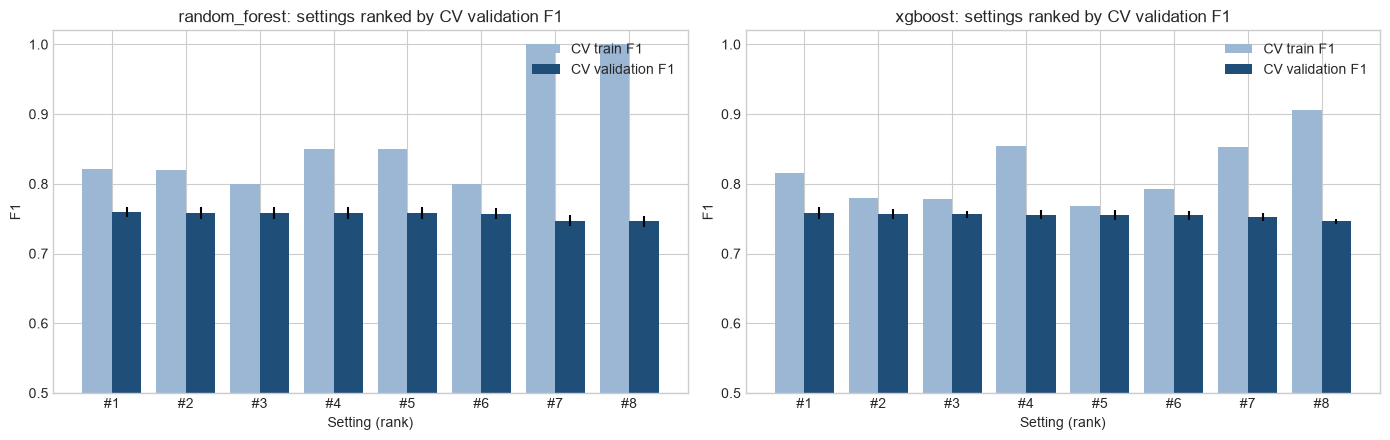

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, table) in zip(axes, cv_tables.items()):
    t = table.reset_index(drop=True)
    labels = [f'#{i + 1}' for i in range(len(t))]
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['cv_train_f1'], width=0.4, label='CV train F1', color='#9bb7d4')
    ax.bar(x + 0.2, t['cv_val_f1'], width=0.4, yerr=t['cv_val_f1_std'], label='CV validation F1', color='#1f4e79')
    ax.set_xticks(x, labels)
    ax.set_ylim(0.5, 1.02)
    ax.set_title(f'{name}: settings ranked by CV validation F1')
    ax.set_xlabel('Setting (rank)')
    ax.set_ylabel('F1')
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. Score once on the test split

Each tuned model (refit on the full training split with its best settings) is scored a single time on the test split. The T09 benchmark, logistic regression with balanced class weights, is refit on the same leakage-safe split so the three models are compared on identical data. Labels use the default 0.5 threshold; T17 will choose the operating threshold from the saved probabilities.

In [7]:
# T09 benchmark refit on the T08 split for a like-for-like comparison.
logreg = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

models = {
    'logistic_regression (T09 benchmark)': logreg,
    'random_forest': best_estimators['random_forest'],
    'xgboost': best_estimators['xgboost'],
}
cv_f1 = {'random_forest': rf_search.best_score_, 'xgboost': xgb_search.best_score_}

probs, rows = {}, []
for name, model in models.items():
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append({
        'model': name,
        'cv_f1': cv_f1.get(name, np.nan),
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, p),
        'average_precision': average_precision_score(y_test, p),
    })

test_results = pd.DataFrame(rows).sort_values('f1', ascending=False).reset_index(drop=True)
test_results.round(4)

,model,cv_f1,accuracy,precision,recall,f1,roc_auc,average_precision
0,random_forest,0.7594,0.8037,0.7078,0.7550,0.7306,0.8753,0.8115
1,xgboost,0.7578,0.7944,0.6880,0.7625,0.7233,0.8743,0.8145
2,logistic_regression (T09 benchmark),NaN,0.7791,0.6574,0.7794,0.7132,0.8722,0.8024


In [8]:
for name in models:
    pred = (probs[name] >= 0.5).astype(int)
    print(f'=== {name} ===')
    print(classification_report(y_test, pred, target_names=['not hallucinated', 'hallucinated'], digits=3))

=== logistic_regression (T09 benchmark) ===
                  precision    recall  f1-score   support

not hallucinated      0.866     0.779     0.820      1732
    hallucinated      0.657     0.779     0.713       943

        accuracy                          0.779      2675
       macro avg      0.762     0.779     0.767      2675
    weighted avg      0.793     0.779     0.783      2675

=== random_forest ===
                  precision    recall  f1-score   support

not hallucinated      0.862     0.830     0.846      1732
    hallucinated      0.708     0.755     0.731       943

        accuracy                          0.804      2675
       macro avg      0.785     0.793     0.788      2675
    weighted avg      0.807     0.804     0.805      2675

=== xgboost ===
                  precision    recall  f1-score   support

not hallucinated      0.863     0.812     0.836      1732
    hallucinated      0.688     0.762     0.723       943

        accuracy                        

## 7. Visual comparison

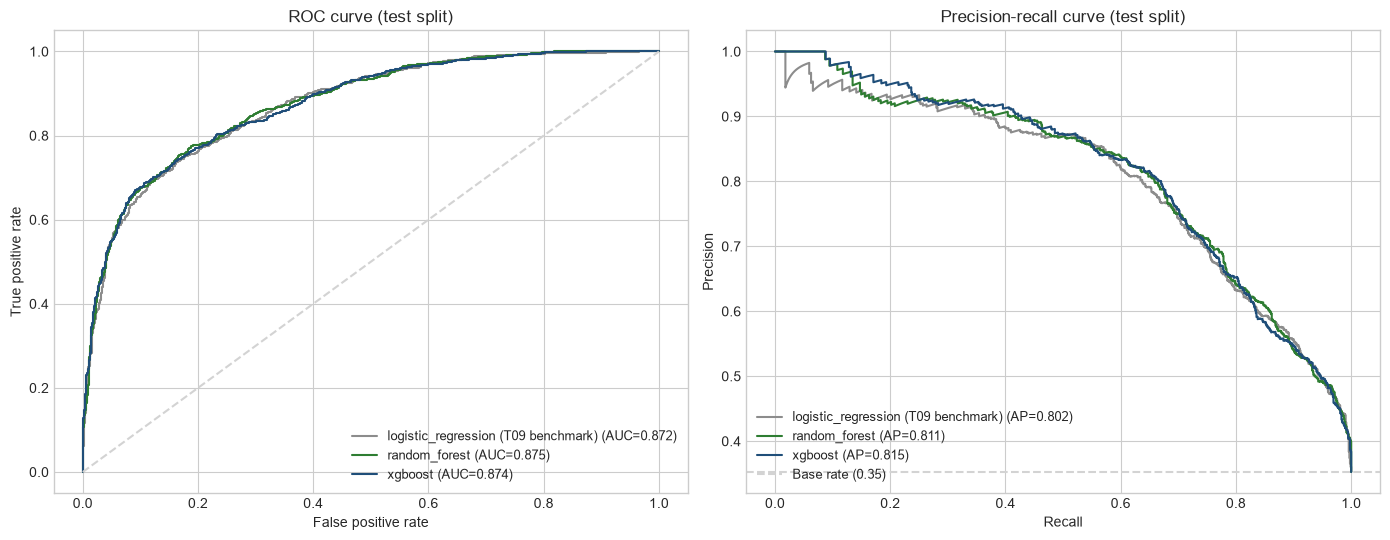

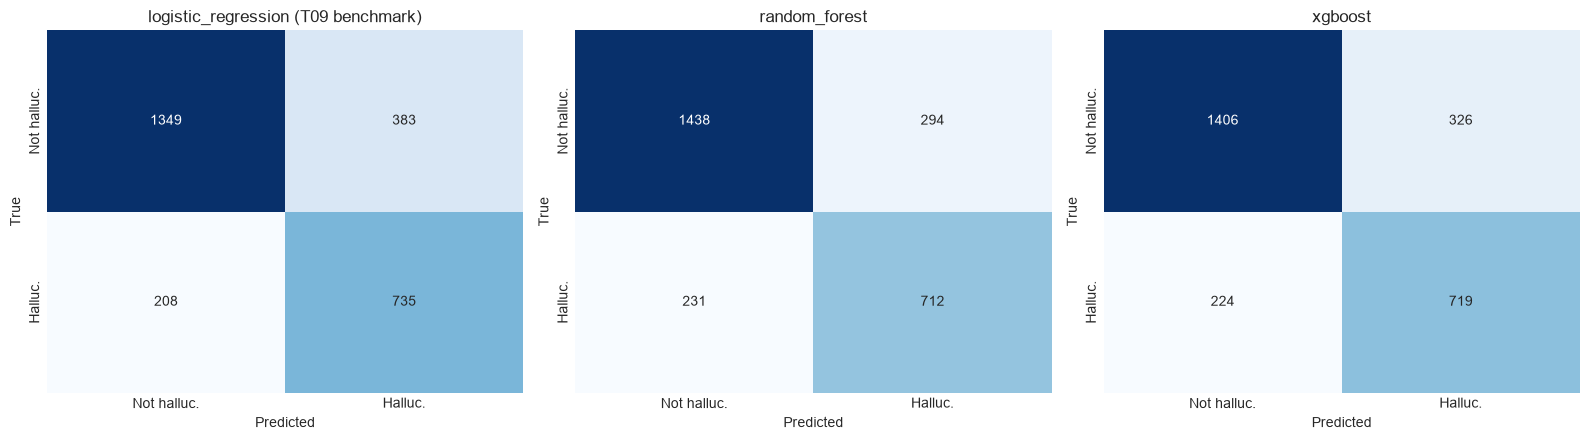

In [9]:
colors = {'logistic_regression (T09 benchmark)': '#8c8c8c', 'random_forest': '#2e7d32', 'xgboost': '#1f4e79'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=colors[name], label=f'{name} (AP={average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], ls='--', color='lightgray')
axes[0].set(title='ROC curve (test split)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), ls='--', color='lightgray', label=f'Base rate ({y_test.mean():.2f})')
axes[1].set(title='Precision-recall curve (test split)', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(loc='lower right' if ax is axes[0] else 'lower left', fontsize=9)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Not halluc.', 'Halluc.'], yticklabels=['Not halluc.', 'Halluc.'])
    ax.set(title=name, xlabel='Predicted', ylabel='True')
plt.tight_layout()
plt.show()

## 8. Save predictions and results

`results/predictions.csv` has one row per test answer with the true label, the LLM that wrote the answer, the task type, and each model's predicted probability of hallucination. Join it to `data/processed/T05_token_counts.csv` on `id` for the cost analysis.

Also saved:
- `results/T12_model_comparison.csv`: test-split metrics for the three models.
- `results/T12_cv_results.csv`: every grid setting with its CV scores.

In [10]:
llm_cols = [c for c in feature_cols if c.startswith('model_')]
task_cols = [c for c in feature_cols if c.startswith('task_type_')]

predictions = pd.DataFrame({
    'id': test_df['id'],
    'source_id': test_df['source_id'],
    'llm': test_df[llm_cols].idxmax(axis=1).str.replace('model_', '', regex=False),
    'task_type': test_df[task_cols].idxmax(axis=1).str.replace('task_type_', '', regex=False),
    'hallucinated': y_test,
    'prob_logreg': probs['logistic_regression (T09 benchmark)'],
    'prob_rf': probs['random_forest'],
    'prob_xgb': probs['xgboost'],
})
predictions.to_csv(results_dir / 'predictions.csv', index=False)
test_results.to_csv(results_dir / 'T12_model_comparison.csv', index=False)
pd.concat([t.assign(model=n) for n, t in cv_tables.items()]).to_csv(results_dir / 'T12_cv_results.csv', index=False)

print(f'Saved {len(predictions):,} rows to results/predictions.csv')
predictions.head()

Saved 2,675 rows to results/predictions.csv


,id,source_id,llm,task_type,hallucinated,prob_logreg,prob_rf,prob_xgb
0,24,15596,gpt-4-0613,Summary,0,0.045398,0.062379,0.076949
1,25,15596,gpt-3.5-turbo-0613,Summary,0,0.035651,0.072341,0.060201
2,26,15596,mistral-7B-instruct,Summary,0,0.451564,0.244671,0.086956
3,27,15596,llama-2-7b-chat,Summary,0,0.371114,0.407983,0.322207
4,28,15596,llama-2-13b-chat,Summary,1,0.352752,0.315618,0.271592


## 9. Conclusion

The summary below is computed from the results above, so it stays correct if the notebook is rerun.

In [11]:
best = test_results.iloc[0]
bench = test_results[test_results['model'].str.startswith('logistic')].iloc[0]
print(f"Best model on test F1: {best['model']} (F1 = {best['f1']:.3f}, ROC-AUC = {best['roc_auc']:.3f}, "
      f"recall = {best['recall']:.3f}, precision = {best['precision']:.3f})")
print(f"T09 benchmark (logistic regression): F1 = {bench['f1']:.3f}, ROC-AUC = {bench['roc_auc']:.3f}")
for _, r in test_results.iterrows():
    if r['model'] != bench['model']:
        print(f"  {r['model']}: F1 {r['f1'] - bench['f1']:+.3f}, ROC-AUC {r['roc_auc'] - bench['roc_auc']:+.3f}, "
              f"AP {r['average_precision'] - bench['average_precision']:+.3f} vs. benchmark")
print('\nBest settings:')
print('  random_forest:', rf_search.best_params_)
print('  xgboost:      ', xgb_search.best_params_)

Best model on test F1: random_forest (F1 = 0.731, ROC-AUC = 0.875, recall = 0.755, precision = 0.708)
T09 benchmark (logistic regression): F1 = 0.713, ROC-AUC = 0.872
  random_forest: F1 +0.017, ROC-AUC +0.003, AP +0.009 vs. benchmark
  xgboost: F1 +0.010, ROC-AUC +0.002, AP +0.012 vs. benchmark

Best settings:
  random_forest: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
  xgboost:       {'model__learning_rate': 0.05, 'model__max_depth': 6, 'model__n_estimators': 200}
